# Figure 8-5 — derating

Stresses are the nodal solution at the 250 kHz, 1 V peak tone, with the
input bias at 0 V. Resistor power is Vdc²/R + |Vac|²/(2R). Capacitor
voltage is |Vdc| + |Vac|. The op-amp supply stress is the 5 V span.
Dissipation is that span times the 4.6 mA typical quiescent current, plus
the load power in 10 kΩ.

Limits used in this study: 0805 resistors, 0.125 W full to 70 °C, linearly
to 0 W at 155 °C, and a 50% use of the derated power. The resistor
working-voltage guideline is 150 V. Capacitors are 50 V parts used at or
below half of that rating. The OPA365 recommended supply used here is
2.2 V to 5.5 V, and the package allowance used here is 0.5 W. That
allowance is a study number, not a thermal-resistance calculation.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


In [3]:
from mfb_design.derating import (
    evaluate_derating, passband_stresses, power_derating_curve, stress_vs_limits,
)

stress = passband_stresses(p)
for s in stress:
    print(f"{s.name:8s}  Vpk={s.v_peak:.6g} V  Irms={s.i_rms_est:.6g} A  P={s.p_est:.6g} W")
table = evaluate_derating(p, temp_c=25.0, stresses=stress)
display(table)
table.to_csv(ROOT / "results" / "derating_table_25C.csv", index=False)
print("All rows pass the study limits:" , bool(table["pass"].all()))


R1        Vpk=0.83049 V  Irms=0.00106966 A  P=0.000628154 W
R2        Vpk=0.282592 V  Irms=0.000161147 A  P=3.22008e-05 W
R3        Vpk=1.00766 V  Irms=0.00129786 A  P=0.000924752 W
C1        Vpk=0.282592 V  Irms=0.00031388 A  P=0 W
C2        Vpk=0.967223 V  Irms=0.000161147 A  P=0 W
OPA365    Vpk=5 V  Irms=0.0046 A  P=0.0230468 W
All rows pass the study limits: True


component,package_or_rating,stress_type,stress_value,stress_unit,limit_value,derated_full_W,rated_W,margin_percent,pass,notes
R1,0805,power,0.000628154,W,0.0625,0.125,0.125,98.995,True,"250000 Hz, 1 V peak about 0 V"
R1,0805,voltage,0.83049,V,150,0.125,0.125,99.4463,True,"0805 working-voltage guideline, 150 V"
R2,0805,power,3.22008e-05,W,0.0625,0.125,0.125,99.9485,True,"250000 Hz, 1 V peak about 0 V"
R2,0805,voltage,0.282592,V,150,0.125,0.125,99.8116,True,"0805 working-voltage guideline, 150 V"
R3,0805,power,0.000924752,W,0.0625,0.125,0.125,98.5204,True,"250000 Hz, 1 V peak about 0 V"
R3,0805,voltage,1.00766,V,150,0.125,0.125,99.3282,True,"0805 working-voltage guideline, 150 V"
C1,50 V,voltage,0.282592,V,25,NaN,NaN,98.8696,True,peak |Vdc|+|Vac| at 250000 Hz; rule is ≤50% of VR
C2,50 V,voltage,0.967223,V,25,NaN,NaN,96.1311,True,peak |Vdc|+|Vac| at 250000 Hz; rule is ≤50% of VR
OPA365,2.2–5.5 V,supply,5,V,5.5,NaN,NaN,9.09091,True,supply span; Iq typ plus load (46.78 µW)
OPA365,package allowance,power,0.0230468,W,0.5,NaN,NaN,95.3906,True,supply span; Iq typ plus load (46.78 µW)


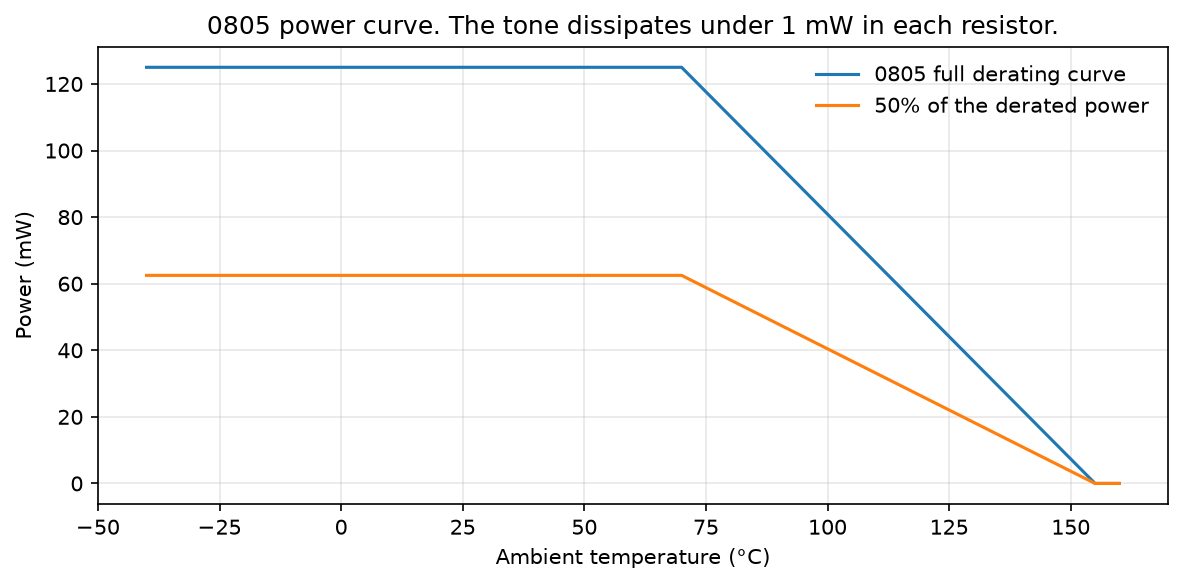

In [4]:
curve = power_derating_curve(p)
fig, ax = plt.subplots(figsize=(8.0, 4.0))
ax.plot(curve["temp_c"], curve["p_rated_curve_W"] * 1e3, label="0805 full derating curve")
ax.plot(curve["temp_c"], curve["p_allow_W"] * 1e3, label="50% of the derated power")
ax.set_xlabel("Ambient temperature (°C)")
ax.set_ylabel("Power (mW)")
ax.set_title("0805 power curve. The tone dissipates under 1 mW in each resistor.")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "08_power_derating_curve.png", dpi=150)
plt.show()


## Applied stress against the rating and the derating limit

Resistor voltages are a few volts at most, against the 150 V guideline, so
they stay in the table. The voltage chart has one panel for the capacitors
and one for the op-amp supply. The power chart uses a log axis so the
resistor dissipation remains visible next to the package allowance.


Every applied stress is below its derated limit.


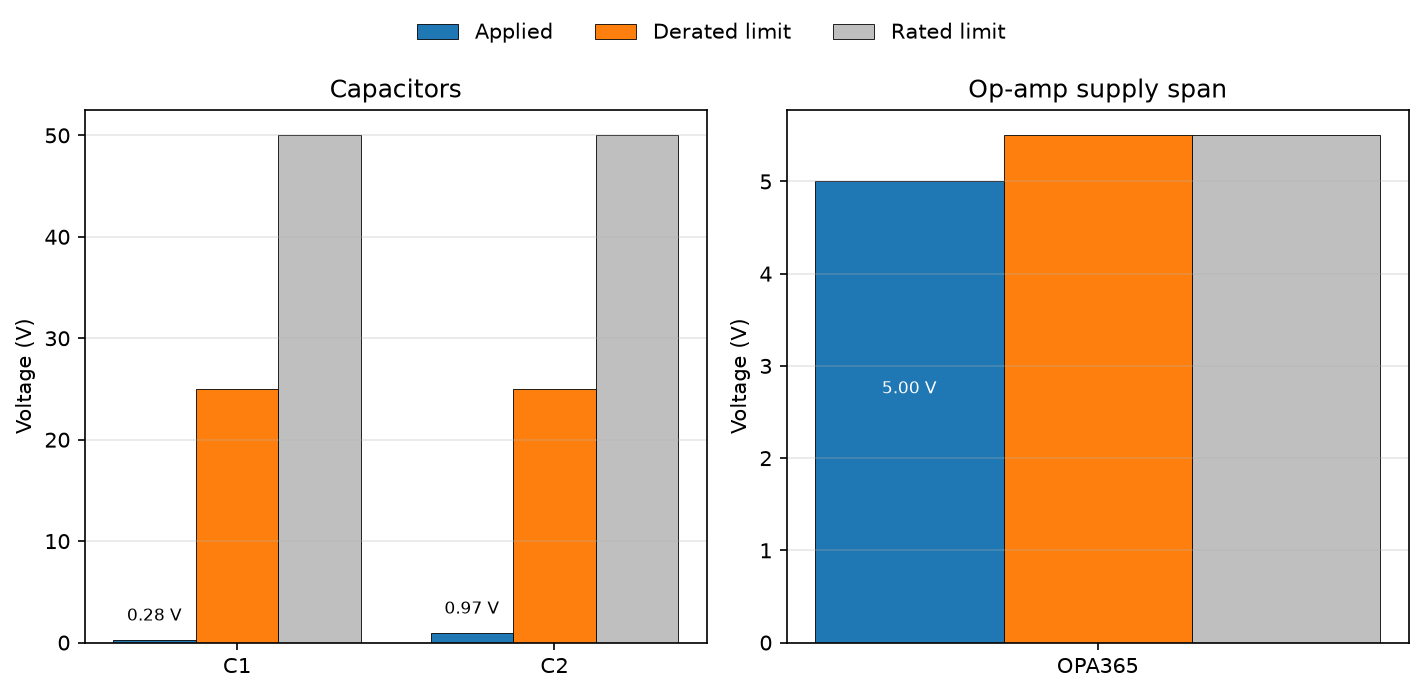

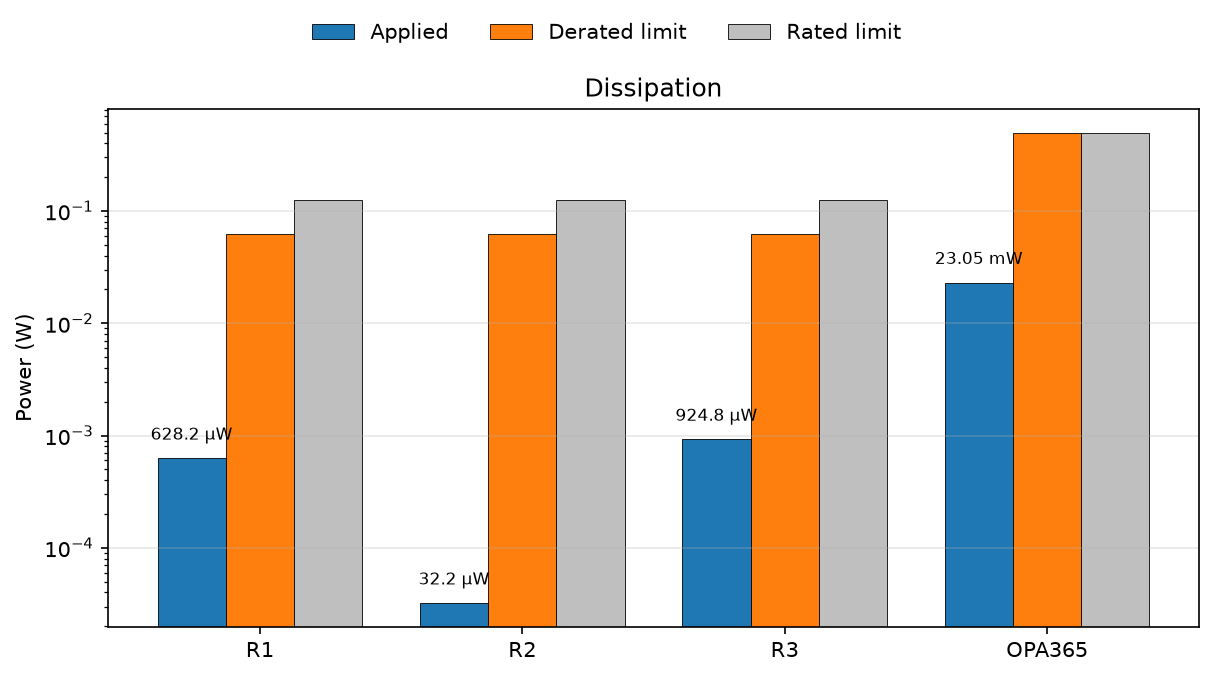

component,quantity,applied,derated_limit,rated_limit,utilization_of_derated_%,notes
R1,voltage,0.83049,150,150,0.55366,0805 working-voltage guideline
R1,power,0.000628154,0.0625,0.125,1.00505,derated limit is 50% of the 25 °C curve
R2,voltage,0.282592,150,150,0.188394,0805 working-voltage guideline
R2,power,3.22008e-05,0.0625,0.125,0.0515213,derated limit is 50% of the 25 °C curve
R3,voltage,1.00766,150,150,0.671773,0805 working-voltage guideline
R3,power,0.000924752,0.0625,0.125,1.4796,derated limit is 50% of the 25 °C curve
C1,voltage,0.282592,25,50,1.13037,≤50% of VR
C2,voltage,0.967223,25,50,3.86889,≤50% of VR
OPA365,voltage,5,5.5,5.5,90.9091,recommended operating maximum
OPA365,power,0.0230468,0.5,0.5,4.60936,package allowance used in this study


In [5]:
lim = stress_vs_limits(p, temp_c=25.0, stresses=stress)
lim.to_csv(ROOT / "results" / "stress_vs_limits.csv", index=False)

def grouped(ax, labels, applied, derated, rated, ylabel, title, log=False):
    x = np.arange(len(labels))
    w = 0.26
    bars = ax.bar(x - w, applied, w, color="C0", edgecolor="k", linewidth=0.4)
    ax.bar(x, derated, w, color="C1", edgecolor="k", linewidth=0.4)
    ax.bar(x + w, rated, w, color="0.75", edgecolor="k", linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    if log:
        ax.set_yscale("log")
    top = float(max(np.max(rated), np.max(applied), np.max(derated)))
    for rect, val in zip(bars, applied):
        color = "k"
        if ylabel.startswith("Power"):
            text = f"{val*1e6:.1f} µW" if val < 1e-3 else f"{val*1e3:.2f} mW"
        else:
            text = f"{val:.2f} V"
        if log:
            y, va = val * 1.35, "bottom"
        elif val > 0.72 * top:
            y, va, color = val * 0.55, "center", "white"
        else:
            y, va = val + 0.03 * top, "bottom"
        ax.text(rect.get_x() + rect.get_width()/2, y, text, ha="center", va=va, fontsize=8, color=color)

volt = lim[lim["quantity"] == "voltage"]
caps = volt[volt["component"].isin(["C1", "C2"])]
amp = volt[volt["component"] == p.opamp.name]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.3))
grouped(
    axes[0], list(caps["component"]), caps["applied"].to_numpy(),
    caps["derated_limit"].to_numpy(), caps["rated_limit"].to_numpy(),
    "Voltage (V)", "Capacitors",
)
grouped(
    axes[1], list(amp["component"]), amp["applied"].to_numpy(),
    amp["derated_limit"].to_numpy(), amp["rated_limit"].to_numpy(),
    "Voltage (V)", "Op-amp supply span",
)
handles = [
    plt.Rectangle((0, 0), 1, 1, color="C0", ec="k", lw=0.4),
    plt.Rectangle((0, 0), 1, 1, color="C1", ec="k", lw=0.4),
    plt.Rectangle((0, 0), 1, 1, color="0.75", ec="k", lw=0.4),
]
fig.legend(handles, ["Applied", "Derated limit", "Rated limit"],
           loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig(FIG / "08_voltage_bars.png", dpi=150, bbox_inches="tight")
plt.show()

pwr = lim[lim["quantity"] == "power"]
fig, ax = plt.subplots(figsize=(8.2, 4.2))
grouped(
    ax, list(pwr["component"]), pwr["applied"].to_numpy(),
    pwr["derated_limit"].to_numpy(), pwr["rated_limit"].to_numpy(),
    "Power (W)", "Dissipation", log=True,
)
fig.legend(handles, ["Applied", "Derated limit", "Rated limit"],
           loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig(FIG / "08_power_bars.png", dpi=150, bbox_inches="tight")
plt.show()

rows = []
for _, r in lim.iterrows():
    rows.append({
        "component": r["component"],
        "quantity": r["quantity"],
        "applied": r["applied"],
        "derated_limit": r["derated_limit"],
        "rated_limit": r["rated_limit"],
        "utilization_of_derated_%": 100 * r["utilization_of_derated"],
        "notes": r["notes"],
    })
display(pd.DataFrame(rows))
if bool((lim["utilization_of_derated"] < 1.0).all()):
    print("Every applied stress is below its derated limit.")
else:
    print("At least one applied stress meets or exceeds its derated limit.")
